# 03 · Nowcasting do VSR com incerteza

Em cada origem $o$, a versão de tempo real $y^{(o)}_{u,t}$ (casos disponíveis até $o$) é corrigida pelo atraso para estimar o total final $N_{u,t}$ das semanas $t = o - 8, \dots, o$ ($d = (o - t)/7$). Código em `vsr_nowcast.py`; método em `docs/METODOLOGIA.md` §6.1.

**Modelo** (análogo conjugado de Bastos et al., 2019, sem INLA), por unidade:
$$y_t \mid \lambda_t \sim \text{Pois}(\lambda_t F(d)), \qquad N_t - y_t \mid \lambda_t, \varepsilon \sim \text{Pois}(\varepsilon\,\lambda_t (1 - F(d))), \qquad \varepsilon \sim \text{Gama}(\varphi, \varphi)$$
$$\lambda_t \sim \text{Gama}(k, k/m_t), \quad m_t = \hat\lambda_{t-1}\, g_t \;\Rightarrow\; \lambda_t \mid y_t \sim \text{Gama}(k + y_t,\; k/m_t + F(d))$$
- $k$: força do passeio aleatório (k = 0: *a priori* plana, chain-ladder com incerteza Poisson); $g_t$: tendência recente (razão $\hat\lambda_{t-1}/\hat\lambda_{t-2}$ limitada a [2/3, 1,5]); $\varphi$: superdispersão (erro de $F$).
- $F_r(d)$ da região (UFs e regiões) ou do Brasil, por duas fontes: `maturado` (semanas com $t + D \le o$ dos 3 anos anteriores, igual ao pipeline de `04_modelos`) e `janela` (chain-ladder nas últimas 52 semanas, incluindo as incompletas; capta mudanças recentes no atraso).

**Desenho:** ajuste dos hiperparâmetros nas origens de 2023 (fora da avaliação); avaliação nas origens de 2024 a 2026 contra a verdade final do triângulo. Alvos com $t + D >$ última semana do painel têm verdade ainda em maturação (`verdade_madura = False`) e ficam fora do recorte principal.

**Saídas:** `previsoes_nowcast.parquet` (23 quantis) e `avaliacao_nowcast.parquet`.

In [1]:
import itertools
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import vsr_modelos as vm
import vsr_nowcast as vn
from vsr_comum import P, verificar_ambiente

verificar_ambiente()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

A, SEM = vn.cubo()
OBS = pd.DataFrame({"unidade": np.repeat(vm.ORDEM, len(SEM)), "semana": np.tile(SEM, len(vm.ORDEM)),
                    "vsr": A.sum(2).ravel()})
ULTIMA = SEM[-1]
TIERS = pd.read_csv(P / "tiers_uf.csv").set_index("unidade")["tier"]
print(f"cubo {A.shape} (unidades × semanas × atraso); última semana {ULTIMA.date()}")


def rodar(origens, metodos, semente):
    p = pd.concat([vn.prever_origem(A, SEM, o, metodos, np.random.default_rng(semente + j))
                   for j, o in enumerate(origens)], ignore_index=True)
    sc = vm.pontuar(p.assign(mediana=p["q0.5"]), OBS)
    sc["grupo"] = np.where(sc["nivel"] == "UF", "UF " + sc["unidade"].map(TIERS),
                           np.where(sc["nivel"] == "BRASIL", "BR", "REGIAO"))
    sc["verdade_madura"] = sc["alvo"] + pd.Timedelta(weeks=vm.D) <= ULTIMA
    sc["vies_log"] = np.log1p(sc.pop("mediana")) - np.log1p(sc["obs"])
    return p, sc

cubo (33, 407, 27) (unidades × semanas × atraso); última semana 2026-10-11


## 1. Ajuste em 2023

Grade: fonte `janela`, $k \in \{0, 3, 10\}$, com e sem tendência, $\varphi \in \{\infty, 8, 4\}$; mais o chain-ladder `maturado` do pipeline atual. Critério: WIS em escala log em $d \le 3$, média de agregados (BR + regiões) e UFs, com cobertura de 90% próxima do nominal.

In [2]:
GRADE = {"cl_maturado": dict(fonte="maturado", k=0, tendencia=False)}
for k, t, ph in itertools.product((0, 3, 10), (False, True), (np.inf, 8, 4)):
    if k == 0 and t:
        continue                                   # sem a priori, a tendência não atua
    GRADE[f"k{k}{'t' if t else ''}_phi{ph:g}"] = dict(fonte="janela", k=k, tendencia=t, phi=ph)
t0 = time.time()
_, SC23 = rodar(pd.date_range("2023-01-01", "2023-12-31", freq="7D"), GRADE, vm.SEMENTE)
g = SC23.loc[SC23["d"] <= 3].assign(ag=lambda x: np.where(x["nivel"] == "UF", "UF", "agregado"))
TAB23 = g.pivot_table(index="modelo", columns="ag", values=["wis_log", "cob90"]).round(3)
TAB23["wis_medio"] = TAB23["wis_log"].mean(1)
display(TAB23.sort_values("wis_medio"))
print(f"{time.time() - t0:.0f} s")

C:\Users\joanc\AppData\Local\Temp\ipykernel_15008\2404446391.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  TAB23["wis_medio"] = TAB23["wis_log"].mean(1)


cob90          wis_log          wis_medio
ag               UF agregado      UF agregado          
modelo                                                 
k10_phi8      0.760    0.936   0.157    0.059    0.1080
k10_phi4      0.830    0.977   0.154    0.064    0.1090
k10t_phi8     0.742    0.931   0.167    0.060    0.1135
k10t_phi4     0.815    0.974   0.164    0.065    0.1145
k3_phi8       0.749    0.931   0.172    0.062    0.1170
k10_phiinf    0.614    0.487   0.167    0.067    0.1170
k3_phi4       0.817    0.973   0.170    0.067    0.1185
k3t_phi8      0.738    0.931   0.180    0.062    0.1210
k3t_phi4      0.806    0.974   0.177    0.067    0.1220
k10t_phiinf   0.597    0.492   0.177    0.068    0.1225
k3_phiinf     0.614    0.488   0.181    0.070    0.1255
k0_phi8       0.752    0.925   0.188    0.064    0.1260
k0_phi4       0.827    0.972   0.184    0.068    0.1260
k3t_phiinf    0.606    0.491   0.189    0.070    0.1295
k0_phiinf     0.613    0.481   0.200    0.073    0.1365
cl_maturado   0.586    0.390   0.206    0.092    0.1490
sem_correcao  0.152    0.001   0.605    0.620    0.6125

25 s


**Escolha** (fixada antes de olhar 2024–2026): `gamma_rw` = janela, $k = 10$, tendência, $\varphi = 4$ — melhor WIS nas UFs e cobertura de 90% de ~0,9; as configurações vizinhas ($k \ge 3$, $\varphi \in \{4, 8\}$) diferem pouco. Comparadores: `sem_correcao` ($y^{(o)}$), `chain_ladder` (pipeline atual: `maturado`, *a priori* plana, Poisson) e `cl_janela` (janela, *a priori* plana, $\varphi = 4$), que isola o ganho da fonte de $F$ e da superdispersão do ganho do passeio aleatório.

In [3]:
METODOS = {"chain_ladder": dict(fonte="maturado", k=0, tendencia=False),
           "cl_janela": dict(fonte="janela", k=0, tendencia=False, phi=4),
           "gamma_rw": vn.METODO_PADRAO}
ORIGENS = pd.date_range("2023-12-31", min(ULTIMA, pd.Timestamp("2026-12-27")), freq="7D")
t0 = time.time()
PREV, SC = rodar(ORIGENS, METODOS, vm.SEMENTE + 50_000)
PREV.to_parquet(P / f"previsoes_nowcast{vm.sufixo()}.parquet", index=False)
SC.to_parquet(P / f"avaliacao_nowcast{vm.sufixo()}.parquet", index=False)
PRINC = SC.loc[SC["verdade_madura"]]
print(f"{len(ORIGENS)} origens ({ORIGENS[0].date()} a {ORIGENS[-1].date()}); {len(PREV):,} linhas em "
      f"{time.time() - t0:.0f} s; {PRINC['origem'].max().date()} = última origem com verdade madura em d = 0")

146 origens (2023-12-31 a 2026-10-11); 173,448 linhas em 13 s; 2026-06-07 = última origem com verdade madura em d = 0


## 2. Acurácia e calibração por atraso decorrido (verdade madura)

In [4]:
for met in ("wis_log", "cob50", "cob90", "vies_log"):
    print(met)
    display(PRINC.assign(ag=lambda x: np.where(x["nivel"] == "UF", "UF", x["grupo"]))
            .pivot_table(index=["ag", "modelo"], columns="d", values=met).round(3))

wis_log


d                        0      1      2      3      4      5      6      7      8
ag     modelo                                                                     
BR     chain_ladder  0.135  0.061  0.039  0.030  0.025  0.022  0.018  0.015  0.013
       cl_janela     0.122  0.050  0.030  0.021  0.017  0.014  0.011  0.010  0.009
       gamma_rw      0.121  0.050  0.031  0.021  0.017  0.014  0.011  0.010  0.009
       sem_correcao  1.671  0.426  0.217  0.138  0.098  0.072  0.057  0.047  0.040
REGIAO chain_ladder  0.159  0.071  0.050  0.040  0.034  0.029  0.025  0.022  0.020
       cl_janela     0.142  0.056  0.037  0.027  0.023  0.019  0.016  0.015  0.014
       gamma_rw      0.134  0.056  0.037  0.027  0.023  0.019  0.016  0.015  0.014
       sem_correcao  1.633  0.401  0.199  0.126  0.089  0.066  0.052  0.043  0.037
UF     chain_ladder  0.331  0.175  0.112  0.083  0.067  0.056  0.047  0.041  0.037
       cl_janela     0.299  0.150  0.097  0.071  0.057  0.048  0.041  0.036  0.032
       gamma_rw      0.251  0.145  0.096  0.070  0.057  0.048  0.040  0.036  0.032
       sem_correcao  1.545  0.412  0.209  0.134  0.097  0.074  0.060  0.050  0.043

cob50


d                        0      1      2      3      4      5      6      7      8
ag     modelo                                                                     
BR     chain_ladder  0.092  0.124  0.082  0.065  0.105  0.088  0.071  0.087  0.078
       cl_janela     0.892  0.810  0.844  0.805  0.766  0.728  0.730  0.717  0.711
       gamma_rw      0.892  0.826  0.828  0.789  0.758  0.696  0.746  0.756  0.680
       sem_correcao  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
REGIAO chain_ladder  0.223  0.202  0.195  0.171  0.200  0.218  0.238  0.214  0.233
       cl_janela     0.758  0.767  0.692  0.663  0.619  0.557  0.571  0.576  0.538
       gamma_rw      0.800  0.770  0.685  0.670  0.624  0.555  0.563  0.573  0.547
       sem_correcao  0.000  0.000  0.000  0.000  0.000  0.011  0.017  0.031  0.045
UF     chain_ladder  0.320  0.267  0.287  0.335  0.377  0.411  0.466  0.505  0.527
       cl_janela     0.517  0.460  0.461  0.502  0.556  0.593  0.634  0.671  0.699
       gamma_rw      0.540  0.470  0.469  0.505  0.565  0.596  0.637  0.671  0.693
       sem_correcao  0.007  0.066  0.163  0.240  0.312  0.390  0.439  0.482  0.521

cob90


d                        0      1      2      3      4      5      6      7      8
ag     modelo                                                                     
BR     chain_ladder  0.258  0.215  0.246  0.252  0.194  0.200  0.206  0.220  0.211
       cl_janela     0.983  1.000  1.000  0.992  0.968  0.944  0.905  0.898  0.891
       gamma_rw      0.975  1.000  0.992  0.992  0.976  0.936  0.897  0.906  0.898
       sem_correcao  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
REGIAO chain_ladder  0.518  0.428  0.430  0.442  0.447  0.459  0.486  0.488  0.495
       cl_janela     0.980  0.985  0.964  0.937  0.923  0.906  0.898  0.891  0.866
       gamma_rw      0.982  0.980  0.964  0.941  0.926  0.901  0.892  0.874  0.869
       sem_correcao  0.000  0.000  0.000  0.000  0.000  0.011  0.017  0.031  0.045
UF     chain_ladder  0.652  0.540  0.573  0.637  0.681  0.718  0.747  0.766  0.788
       cl_janela     0.894  0.826  0.826  0.854  0.864  0.875  0.878  0.882  0.879
       gamma_rw      0.880  0.825  0.825  0.849  0.856  0.867  0.874  0.875  0.878
       sem_correcao  0.007  0.066  0.163  0.240  0.312  0.390  0.439  0.482  0.521

vies_log


d                        0      1      2      3      4      5      6      7      8
ag     modelo                                                                     
BR     chain_ladder  0.076  0.039  0.031  0.029  0.026  0.023  0.020  0.017  0.014
       cl_janela    -0.024 -0.016 -0.012 -0.006 -0.005 -0.003 -0.004 -0.003 -0.003
       gamma_rw     -0.028 -0.016 -0.011 -0.006 -0.005 -0.003 -0.004 -0.004 -0.004
       sem_correcao -1.671 -0.426 -0.217 -0.138 -0.098 -0.072 -0.057 -0.047 -0.040
REGIAO chain_ladder  0.103  0.054  0.039  0.036  0.030  0.027  0.023  0.020  0.017
       cl_janela    -0.012 -0.013 -0.010 -0.005 -0.004 -0.003 -0.004 -0.004 -0.004
       gamma_rw     -0.037 -0.016 -0.011 -0.006 -0.004 -0.004 -0.004 -0.004 -0.004
       sem_correcao -1.633 -0.401 -0.199 -0.126 -0.089 -0.066 -0.052 -0.043 -0.037
UF     chain_ladder  0.103  0.027  0.018  0.017  0.012  0.007  0.005  0.002 -0.000
       cl_janela    -0.040 -0.053 -0.037 -0.029 -0.027 -0.025 -0.024 -0.024 -0.023
       gamma_rw     -0.142 -0.067 -0.044 -0.034 -0.031 -0.028 -0.026 -0.025 -0.024
       sem_correcao -1.545 -0.412 -0.209 -0.134 -0.097 -0.074 -0.060 -0.050 -0.043

## 3. WIS relativo ao chain-ladder atual ($d \le 3$)

Razão das médias no conjunto comum de alvos, com IC 95% por bootstrap de origens (`vm.wis_relativo`).

In [5]:
x = PRINC.loc[(PRINC["d"] <= 3) & (PRINC["modelo"] != "sem_correcao")].rename(columns={"d": "h"})
x["ano"] = x["origem"].dt.year
REL = pd.concat([vm.wis_relativo(x, ["grupo"], base="chain_ladder"),
                 vm.wis_relativo(x.assign(grupo="todos"), ["grupo", "ano"], base="chain_ladder")])
display(REL.round(3))

,grupo,modelo,wis_rel,ic_inf,ic_sup,n,ano
0,BR,chain_ladder,1.000,1.000,1.000,486,NaN
1,BR,cl_janela,0.845,0.779,0.923,486,NaN
2,BR,gamma_rw,0.840,0.775,0.921,486,NaN
3,REGIAO,chain_ladder,1.000,1.000,1.000,2430,NaN
4,REGIAO,cl_janela,0.819,0.784,0.854,2430,NaN
5,REGIAO,gamma_rw,0.792,0.753,0.831,2430,NaN
6,UF A,chain_ladder,1.000,1.000,1.000,7290,NaN
7,UF A,cl_janela,0.859,0.841,0.875,7290,NaN
8,UF A,gamma_rw,0.787,0.765,0.807,7290,NaN
9,UF B,chain_ladder,1.000,1.000,1.000,3402,NaN


## 4. Nowcast em tempo real: Brasil e regiões, $d = 0$ e $d = 1$

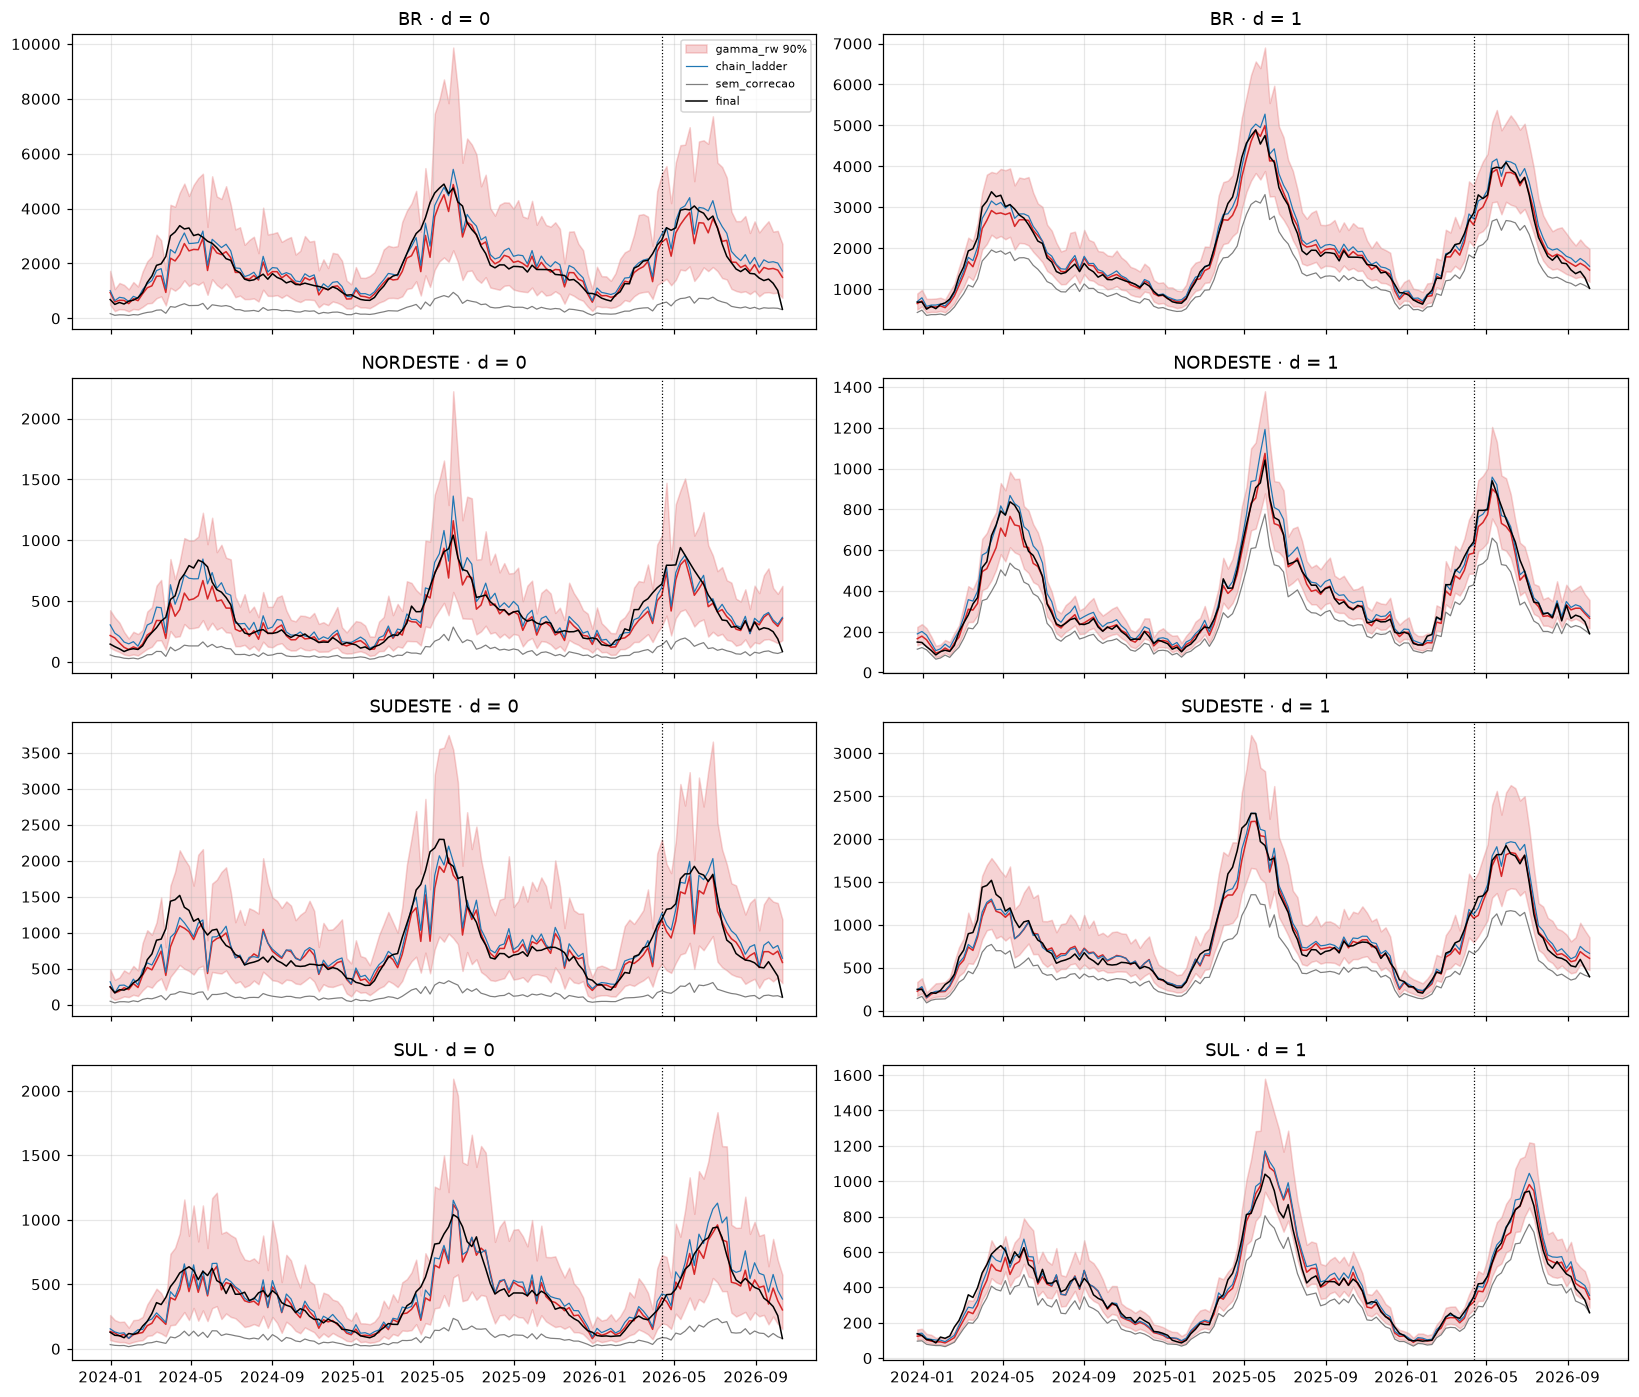

In [6]:
EX = ["BR", "NORDESTE", "SUDESTE", "SUL"]
fig, axs = plt.subplots(len(EX), 2, figsize=(15, 3.2 * len(EX)), sharex=True)
for i, u in enumerate(EX):
    for j, d in enumerate((0, 1)):
        ax = axs[i, j]
        p = PREV.loc[(PREV["unidade"] == u) & (PREV["d"] == d) & (PREV["modelo"] == "gamma_rw")]
        ax.fill_between(p["alvo"], p["q0.05"], p["q0.95"], color="tab:red", alpha=0.2, label="gamma_rw 90%")
        ax.plot(p["alvo"], p["q0.5"], color="tab:red", lw=1)
        for m, cor in (("chain_ladder", "tab:blue"), ("sem_correcao", "tab:gray")):
            q = PREV.loc[(PREV["unidade"] == u) & (PREV["d"] == d) & (PREV["modelo"] == m)]
            ax.plot(q["alvo"], q["q0.5"], color=cor, lw=0.8, label=m)
        o = OBS.loc[(OBS["unidade"] == u) & OBS["semana"].between(p["alvo"].min(), p["alvo"].max())]
        ax.plot(o["semana"], o["vsr"], color="k", lw=1, label="final")
        ax.axvline(ULTIMA - pd.Timedelta(weeks=vm.D), color="k", ls=":", lw=0.8)
        ax.set_title(f"{u} · d = {d}")
axs[0, 0].legend(fontsize=7); fig.tight_layout()

## 5. Resumo

In [7]:
r = PRINC.loc[PRINC["d"] <= 3].assign(ag=lambda x: np.where(x["nivel"] == "UF", "UF", "BR + regiões"))
print(r.groupby(["ag", "modelo"])[["wis_log", "cob50", "cob90", "vies_log"]].mean().round(3).to_string())
print("\nd = 0:")
print(r.loc[r["d"] == 0].groupby(["ag", "modelo"])[["wis_log", "cob90", "vies_log"]].mean().round(3).to_string())

                           wis_log  cob50  cob90  vies_log
ag           modelo                                       
BR + regiões chain_ladder    0.077  0.180  0.419     0.055
             cl_janela       0.064  0.739  0.971    -0.011
             gamma_rw        0.062  0.748  0.971    -0.017
             sem_correcao    0.589  0.000  0.000    -0.589
UF           chain_ladder    0.175  0.302  0.601     0.041
             cl_janela       0.153  0.485  0.850    -0.039
             gamma_rw        0.140  0.496  0.845    -0.071
             sem_correcao    0.570  0.120  0.120    -0.570

d = 0:
                           wis_log  cob90  vies_log
ag           modelo                                
BR + regiões chain_ladder    0.155  0.475     0.099
             cl_janela       0.139  0.981    -0.014
             gamma_rw        0.132  0.981    -0.036
             sem_correcao    1.639  0.000    -1.639
UF           chain_ladder    0.331  0.652     0.103
             cl_janela       0.299  0.